# Real World Data Cleaning — Healthcare Patient Intake Records
**Author:** Alejandro Molina  
**GitHub:** chooseyourtacoday  
**Dataset:** Synthetic DFW Healthcare Patient Intake (1,050 records)  
**Purpose:** Demonstrate end-to-end data cleaning skills on realistically messy healthcare data — the kind of problems every analyst encounters in production environments.

**Mock Scenario:** Every department and individual medical employee inputs patient information differently, causing confusion and delays in patient care. Recently, a patient with O- blood type was administered O+ blood during surgery and expired due to acute hemolytic transfusion reaction. In response, hospital leadership mandated standardization of all patient data entry. As the assigned data analyst, I was tasked with cleaning and organizing the existing dataset to ensure accuracy and prevent recurrence of this tragic incident.

---

## Known Issues to Fix
1. Inconsistent date formats across 5 different styles
2. Inconsistent phone number formats
3. Messy blood type values (mixed case, abbreviations, text)
4. Messy gender values (M/F/male/MALE/etc.)
5. Messy state values (TX/Texas/Tex/tx)
6. Messy department name variations
7. Missing values across 8 columns
8. Impossible outliers (hemoglobin=99.9, weight=999, future dates)
9. Duplicate records with name casing variations
10. Mixed case emails
11. Leading/trailing whitespace in names
12. Future admission dates (2099)
13. Negative donation values

---


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 50)

print("Libraries loaded.")


Libraries loaded.


## 1. Load and Initial Inspection

Looking at the data types I spot several inconsistencies. Both date_of_birth and admission_date are stored as objects rather than datetime64, which means Python cannot perform date calculations or chronological sorting on them. Phone numbers are also stored as objects with inconsistent formatting across five different styles. These need to be standardized — dates converted to datetime64 and phone numbers cleaned to a consistent string format.

In [2]:
df = pd.read_csv("patient_data_MESSY.csv")

# Inspect data types for columns
print(f"Shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
print(f"\nData Types:")
print(df.dtypes)


Shape: (1050, 16)

Columns: ['patient_id', 'first_name', 'last_name', 'date_of_birth', 'admission_date', 'gender', 'blood_type', 'phone', 'email', 'state', 'zip_code', 'department', 'num_visits', 'last_donation_ml', 'hemoglobin', 'weight_lbs']

Data Types:
patient_id           object
first_name           object
last_name            object
date_of_birth        object
admission_date       object
gender               object
blood_type           object
phone                object
email                object
state                object
zip_code            float64
department           object
num_visits            int64
last_donation_ml    float64
hemoglobin          float64
weight_lbs          float64
dtype: object


In [3]:
print("First 5 rows:")
df.head()


First 5 rows:


,patient_id,first_name,last_name,date_of_birth,admission_date,gender,blood_type,phone,email,state,zip_code,department,num_visits,last_donation_ml,hemoglobin,weight_lbs
0,PT-00353,Grant,Brown,10/03/1977,05-02-2022,M,B Positive,173.530.7323,richard67@example.org,TX,78287.0,Phlebotmy,1,475.0,11.4,0.0
1,PT-00690,Michael,Stevenson,2003-12-16,"December 26, 2023",NB,O-,(542) 766-7881,carolynperez@example.org,TX,79124.0,Emergency,5,411.0,16.3,229.0
2,PT-00486,Kim,Anderson,2001-12-15,04-23-21,Female,A+,8927435500,BRANDON27@EXAMPLE.ORG,TX,78657.0,Cardiology,15,413.0,15.0,253.0
3,PT-00389,Shelley,Cochran,"August 02, 2002",2022-01-09,Male,AB+,772.930.4328,wardjoseph@example.com,TX,79419.0,Emergency,19,418.0,14.7,158.0
4,PT-00032,Christina,Watson,07-01-44,2024-07-20,Non-Binary,B+,(998) 437-3249,NaN,TX,78960.0,Phlebotomy,17,410.0,16.5,127.0


There are a sizeable number of missing values across patient records. Most critically, 12% of blood_type entries are missing — and as demonstrated by the recent tragedy involving our O- patient, gaps in blood type documentation carry life-threatening consequences. These records require immediate follow-up with the originating departments.

Additionally, 9% of hemoglobin values are missing. This is clinically significant — donors with low hemoglobin levels, defined as below 13.2 g/dL for males and below 12.0 g/dL for females, pose a potential risk to patients requiring blood transfusions. A donor with insufficient hemoglobin may compromise the quality of the donated blood, putting already vulnerable patients at further risk. These missing values cannot be imputed or estimated — they must be obtained through direct clinical measurement and re-entry by qualified staff.

Gender data shows 11.52% missing values, with additional complexity in the existing entries. The dataset contains gender identity values including Non-binary and Prefer not to say categories. In a clinical context, biological sex is the relevant variable for determining hemoglobin thresholds and transfusion compatibility — not gender identity. However, the dataset does not distinguish between the two.
This represents a data governance decision that falls outside the scope of data cleaning alone. A recommendation has been escalated to hospital leadership and clinical staff to clarify whether a separate biological sex field should be added to patient intake forms, ensuring both patient identity and clinical accuracy are properly captured without compromising either

Hemoglobin thresholds vary based on biological and hormonal factors. Given the complexity of accurately categorizing this data, a recommendation has been made to clinical staff that hemoglobin be verified through direct testing rather than estimated from demographic fields alone.

In [4]:
print("Missing Values Summary:")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print(missing_df[missing_df['Missing Count'] > 0])


Missing Values Summary:
                  Missing Count  Missing %
gender                      121      11.52
blood_type                  129      12.29
phone                        84       8.00
email                       106      10.10
zip_code                     62       5.90
last_donation_ml             51       4.86
hemoglobin                   91       8.67
weight_lbs                   40       3.81


## 2. Pre-Cleaning Snapshot

The pre-cleaning snapshot reveals the full scope of data quality issues inherited from inconsistent data entry practices across departments.
A total of 684 missing values exist across the 1,050 patient records — a 65% data completeness rate that falls well below acceptable clinical standards. Fifty duplicate Patient IDs were identified, representing 4.76% of all records, meaning nearly 1 in 20 patients may have conflicting or redundant information on file.

Blood type entries show 20 unique values where only 8 standard classifications exist (A+, A-, B+, B-, AB+, AB-, O+, O-), confirming widespread inconsistent entry. Gender values contain 16 variations where a standardized set of 4 categories should exist. State values show 8 variations all representing Texas — the same state entered 8 different ways by different staff members.

Each of these inconsistencies represents a point of failure where incorrect data could produce the wrong clinical outcome for a patient. The O- transfusion incident is a direct consequence of this environment.

In [5]:
# Record issues BEFORE cleaning for final comparison report
issues_before = {
    'Total Rows': len(df),
    'Missing Values': df.isnull().sum().sum(),
    'Duplicate Patient IDs': df.duplicated(subset=['patient_id']).sum(),
    'Unique Blood Type Values': df['blood_type'].nunique(),
    'Unique Gender Values': df['gender'].nunique(),
    'Unique State Values': df['state'].nunique(),
    'Unique Department Values': df['department'].nunique(),
}

print("PRE-CLEANING ISSUES SNAPSHOT:")
print("=" * 40)
for k, v in issues_before.items():
    print(f"  {k:35} {v}")


PRE-CLEANING ISSUES SNAPSHOT:
  Total Rows                          1050
  Missing Values                      684
  Duplicate Patient IDs               50
  Unique Blood Type Values            20
  Unique Gender Values                16
  Unique State Values                 8
  Unique Department Values            14


In [6]:
# Show sample of dirty values
print("Sample blood_type values:", df['blood_type'].dropna().unique()[:15])
print("\nSample gender values:", df['gender'].dropna().unique()[:15])
print("\nSample state values:", df['state'].dropna().unique()[:10])
print("\nSample department values:", df['department'].dropna().unique()[:12])
print("\nSample date_of_birth values:", df['date_of_birth'].dropna().unique()[:8])
print("\nSample phone values:", df['phone'].dropna().unique()[:6])


Sample blood_type values: ['B Positive' 'O-' 'A+' 'AB+' 'B+' 'unknown' 'A +' 'AB-' 'B-' 'A-' 'O+'
 'AB' 'A+ ' 'a+' 'A Pos']

Sample gender values: ['M' 'NB' 'Female' 'Male' 'Non-Binary' 'm' 'F' 'female' 'non binary'
 'Non-binary' 'Prefer not to say' 'Other' 'MALE' 'f' 'male']

Sample state values: ['TX' 'Tx' 'tx' 'T X' 'Texas' 'TX.' 'Tex' 'TEXAS']

Sample department values: ['Phlebotmy' 'Emergency' 'Cardiology' 'Phlebotomy' 'Gen' 'CARDIOLOGY'
 'General' 'PHLEBOTOMY' 'Oncology' 'ER' 'Oncologgy' 'cardiology']

Sample date_of_birth values: ['10/03/1977' '2003-12-16' '2001-12-15' 'August 02, 2002' '07-01-44'
 '01-18-81' '01/30/1947' '02-09-01']

Sample phone values: ['173.530.7323' '(542) 766-7881' '8927435500' '772.930.4328'
 '(998) 437-3249' '132-322-7128']


## 3. Data Cleaning — Step by Step

Patient names across the dataset contain leading and trailing whitespace, inconsistent casing variations including fully uppercase and fully lowercase entries, introduced by different staff members entering data without a standardized format. These inconsistencies may seem minor compared to blood type or hemoglobin errors, but their consequences are not. A name search returning no results because of a trailing space or incorrect casing could delay critical care at the exact moment a patient needs it most.

Email addresses present a similar issue — entries were found in fully uppercase format, which is invalid by email standards and would cause any automated communication system to fail silently. A patient who does not receive a critical follow-up notification because their email was entered in the wrong case is a patient whose care has been compromised.
    
Both fields have been standardized — names stripped of whitespace and formatted in title case, emails converted to lowercase. These are small fixes with outsized consequences if left unaddressed.

### Step 1 — Fix Whitespace in Names and Standardize Case

In [7]:
# Strip leading/trailing whitespace and title case names
df['first_name'] = df['first_name'].str.strip().str.title()
df['last_name']  = df['last_name'].str.strip().str.title()

print("Sample names after cleaning:")
print(df[['first_name', 'last_name']].head(8))


Sample names after cleaning:
  first_name  last_name
0      Grant      Brown
1    Michael  Stevenson
2        Kim   Anderson
3    Shelley    Cochran
4  Christina     Watson
5     Denise  Rodriguez
6    Anthony     Garcia
7     Alyssa      Green


### Step 2 — Standardize Email Addresses

In [8]:
# Emails should be lowercase
df['email'] = df['email'].str.lower().str.strip()

print("Sample emails after cleaning:")
print(df['email'].dropna().head(6).tolist())


Sample emails after cleaning:
['richard67@example.org', 'carolynperez@example.org', 'brandon27@example.org', 'wardjoseph@example.com', 'ashley18@example.com', 'jmorris@example.com']


### Step 3 — Standardize Date Formats

Date entries across the dataset were found in five different formats — including MM/DD/YYYY, DD-MM-YYYY, YYYY-MM-DD, written month formats such as 'April 15, 2021', and two-digit year abbreviations like MM-DD-YY. This inconsistency reflects years of unstandardized data entry across departments with no enforced format requirement.
    
All dates have been standardized to YYYY-MM-DD format. While this is not the conventional US date format, it is the ISO 8601 international standard — and for good reason. Blood banks do not always operate within a single state or country. In rare but critical situations, blood products are shipped across state lines or internationally to meet urgent demand. A dataset that will only ever be read by one system in one country is an assumption no hospital should make.

Standardizing to ISO 8601 ensures that patient records remain unambiguous and machine-readable regardless of where they are processed. MM/DD/YYYY and DD/MM/YYYY are visually identical in certain date combinations — a confusion that in a clinical context is not an inconvenience but a liability.

In [9]:
def parse_date(date_str):
    """
    Try multiple date formats and return standardized YYYY-MM-DD.
    Returns NaT if unparseable.
    """
    if pd.isna(date_str):
        return pd.NaT
    
    formats = [
        "%m/%d/%Y", "%Y-%m-%d", "%d-%m-%Y",
        "%B %d, %Y", "%m-%d-%y", "%m/%d/%y"
    ]
    for fmt in formats:
        try:
            return datetime.strptime(str(date_str).strip(), fmt)
        except:
            continue
    return pd.NaT

df['date_of_birth']  = df['date_of_birth'].apply(parse_date)
df['admission_date'] = df['admission_date'].apply(parse_date)

print(f"Unparseable DOB dates:       {df['date_of_birth'].isna().sum()}")
print(f"Unparseable admission dates: {df['admission_date'].isna().sum()}")
print(f"\nSample parsed dates:")
print(df[['date_of_birth', 'admission_date']].dropna().head(5))


Unparseable DOB dates:       0
Unparseable admission dates: 0

Sample parsed dates:
  date_of_birth admission_date
0    1977-10-03     2022-02-05
1    2003-12-16     2023-12-26
2    2001-12-15     2021-04-23
3    2002-08-02     2022-01-09
4    2044-07-01     2024-07-20


### Step 4 — Remove Impossible Future Admission Dates

Fifteen patient records contained admission dates entered as 12/31/2099 — a placeholder value entered by staff when the system required a date but the actual date was unknown or unavailable. These are not real dates. They are data entry workarounds that corrupt any timeline analysis and must be nulled out.
    
In a general dataset this would be a minor inconvenience. In a blood bank it carries deeper implications. Consistent, accurate donation records are essential to maintaining an adequate blood supply for patients who depend on it to survive. Among the most vulnerable are cancer patients, who frequently require platelet transfusions to manage the effects of chemotherapy and disease progression.
    
Platelets are remarkable and fragile. They represent less than 1% of a blood donation by volume. They cannot be stockpiled — their shelf life is only seven days, meaning the supply must be constantly replenished by willing donors. A single donation can sustain one cancer patient through a critical window of treatment.
    
A record with a corrupted admission date is a record that cannot be trusted. It cannot be used to track donation history, verify eligibility, or ensure continuity of care. For a cancer patient waiting on platelets, a data entry error is not an administrative problem — it is a gap in their lifeline.

In [10]:
today = datetime.today()

future_mask = df['admission_date'] > today
print(f"Future admission dates found: {future_mask.sum()}")
print(df.loc[future_mask, ['patient_id', 'admission_date']])

# Flag as NaT — cannot know correct date
df.loc[future_mask, 'admission_date'] = pd.NaT
print(f"\nFuture dates nulled out: {future_mask.sum()} records")


Future admission dates found: 15
     patient_id admission_date
8      PT-00108     2099-12-31
46     PT-00087     2099-12-31
56     PT-00050     2099-12-31
230    PT-00313     2099-12-31
315    PT-00282     2099-12-31
317    PT-00535     2099-12-31
320    PT-00491     2099-12-31
349    PT-00466     2099-12-31
383    PT-00449     2099-12-31
585    PT-00237     2099-12-31
599    PT-00981     2099-12-31
656    PT-00116     2099-12-31
964    PT-00462     2099-12-31
977    PT-00477     2099-12-31
1023   PT-00236     2099-12-31

Future dates nulled out: 15 records


### Step 5 — Standardize Blood Type

All blood type entries must be standardized to the eight universally recognized classifications: A+, A-, B+, B-, AB+, AB-, O+, and O-. This is not a debate — it is a clinical requirement.
    
The current dataset contains 20 variations of blood type entry. Abbreviations, misspellings, mixed casing, and ambiguous entries like 'AB' or 'unknown' have no place in a patient's medical record. Negligence in this single field cost one patient their life. This dataset was flagged before another incident occurred — but that is not a success. It is a warning.

One person is too many for negligence. Every ambiguous blood type entry in this dataset represents a patient whose safety cannot be guaranteed until their record is corrected and verified by clinical staff. Standardization is not optional. It is the baseline from which patient safety begins.

In [11]:
def standardize_blood_type(val):
    """Map messy blood type values to standard format."""
    if pd.isna(val):
        return np.nan
    
    val = str(val).strip().upper()
    
    mapping = {
        'A+': 'A+', 'A POSITIVE': 'A+', 'A POS': 'A+', 'A +': 'A+',
        'A-': 'A-', 'A NEGATIVE': 'A-', 'A NEG': 'A-',
        'B+': 'B+', 'B POSITIVE': 'B+', 'B POS': 'B+',
        'B-': 'B-', 'B NEGATIVE': 'B-', 'B NEG': 'B-',
        'AB+': 'AB+', 'AB POSITIVE': 'AB+', 'AB POS': 'AB+',
        'AB-': 'AB-', 'AB NEGATIVE': 'AB-', 'AB NEG': 'AB-',
        'O+': 'O+', 'O POSITIVE': 'O+', 'O POS': 'O+',
        'O-': 'O-', 'O NEGATIVE': 'O-', 'O NEG': 'O-',
        'UNKNOWN': np.nan, 'AB': np.nan  # Incomplete — treat as missing
    }
    
    return mapping.get(val, np.nan)

df['blood_type'] = df['blood_type'].apply(standardize_blood_type)

print("Blood type value counts after cleaning:")
print(df['blood_type'].value_counts(dropna=False))


Blood type value counts after cleaning:
blood_type
A+     176
NaN    176
O+     135
O-     119
A-      97
B+      95
AB+     93
B-      88
AB-     71
Name: count, dtype: int64


### Step 6 — Standardize Gender

Gender values across the dataset contained 16 variations of what should be a standardized field — entries including M, F, male, MALE, female, NB, Non-Binary, and blank fields among others. These have been standardized to four categories: Male, Female, Non-binary, and Prefer not to say.

However, this step requires an important clinical footnote. In a blood donation context, gender identity and biological sex are not interchangeable variables. Hemoglobin thresholds, donation eligibility, and transfusion compatibility are determined by biological and hormonal factors — not gender identity. A transgender donor on hormone therapy may present hemoglobin levels that do not align with their birth sex, and a Non-binary entry alone provides no clinical guidance whatsoever.

This dataset does not currently distinguish between gender identity and biological sex. That distinction cannot be resolved through data cleaning alone — it requires a policy decision by clinical leadership. A formal recommendation has been escalated to add a separate biological sex field to patient intake forms, verified through direct clinical assessment rather than self-reported entry.

Until that field exists, hemoglobin must be verified through direct testing for every donor regardless of their gender entry. No assumption should be made based on this field alone.

In [12]:
def standardize_gender(val):
    """Map messy gender values to standard categories."""
    if pd.isna(val) or str(val).strip() == '':
        return np.nan
    
    val = str(val).strip().upper()
    
    if val in ['M', 'MALE']:
        return 'Male'
    elif val in ['F', 'FEMALE']:
        return 'Female'
    elif val in ['NON-BINARY', 'NON BINARY', 'NB']:
        return 'Non-binary'
    elif val in ['N/A', 'OTHER', 'PREFER NOT TO SAY']:
        return 'Prefer not to say'
    else:
        return np.nan

df['gender'] = df['gender'].apply(standardize_gender)

print("Gender value counts after cleaning:")
print(df['gender'].value_counts(dropna=False))


Gender value counts after cleaning:
gender
Female               259
Male                 251
Non-binary           234
Prefer not to say    185
NaN                  121
Name: count, dtype: int64


### Step 7 — Standardize State

State entries across the dataset contained 8 variations of Texas — including 'Texas', 'tx', 'Tex', 'TEXAS', 'T X', and 'TX.' among others. All entries have been standardized to the two-letter abbreviation 'TX' in accordance with the USPS standard for state codes.

While this may appear to be a cosmetic issue, the consequences of inconsistent state entries are practical and immediate. Any system query filtering by state — whether pulling patient records, routing shipments of blood products, or generating regional reports — will return incomplete results if the same state is stored under eight different values. A search for 'TX' will miss every record entered as 'Texas' or 'tx'.

Standardization to a two-letter code also reduces future data entry errors. A dropdown or validated field requiring exactly two characters eliminates the variation entirely at the point of entry — which is where data quality problems should be stopped, not cleaned up after the fact.

In [13]:
def standardize_state(val):
    """Map all Texas variations to TX."""
    if pd.isna(val):
        return np.nan
    val = str(val).strip().upper().replace('.', '').replace(' ', '')
    texas_variants = ['TX', 'TEXAS', 'TEX']
    return 'TX' if val in texas_variants else val

df['state'] = df['state'].apply(standardize_state)

print("State value counts after cleaning:")
print(df['state'].value_counts(dropna=False))


State value counts after cleaning:
state
TX    1050
Name: count, dtype: int64


### Step 8 — Standardize Department Names

Department entries contained 12 variations across 5 departments — including abbreviations such as 'ER', 'Gen', and 'PHLE', fully uppercase entries, and misspellings such as 'Phlebotmy' and 'Oncologgy'. All entries have been standardized to their full department titles: Phlebotomy, Oncology, Cardiology, General, and Emergency.

Abbreviations have no place in a clinical record system shared across departments. What reads as obvious shorthand to one staff member may be unfamiliar or ambiguous to another — particularly in high-pressure situations where there is no time to interpret unclear entries. A nurse pulling a patient record during an emergency should not have to pause and decipher whether 'Gen' means General, Genetics, or something else entirely.

Speed and clarity between departments is not a convenience — it is a patient safety requirement. Full department titles eliminate ambiguity at the point of communication, ensuring that the right team receives the right information without hesitation. Going forward, department fields should be enforced through a dropdown selection rather than free text entry, removing the possibility of abbreviations, misspellings, or nonstandard variations entirely."

In [14]:
def standardize_department(val):
    """Map messy department names to standard values."""
    if pd.isna(val):
        return np.nan
    
    val = str(val).strip().upper()
    
    if 'PHLE' in val:
        return 'Phlebotomy'
    elif 'ONCO' in val:
        return 'Oncology'
    elif 'CARDI' in val:
        return 'Cardiology'
    elif val in ['GEN', 'GENERAL']:
        return 'General'
    elif val in ['ER', 'EMERGENCY']:
        return 'Emergency'
    else:
        return val.title()

df['department'] = df['department'].apply(standardize_department)

print("Department value counts after cleaning:")
print(df['department'].value_counts(dropna=False))


Department value counts after cleaning:
department
Cardiology    227
Emergency     222
Phlebotomy    219
General       219
Oncology      163
Name: count, dtype: int64


### Step 9 — Fix Impossible Numeric Outliers

The hemoglobin column contains 32 values at physiologically impossible levels — including entries as absurd as 99.9 g/dL, -1.0 g/dL, and 55.0 g/dL. Similarly, weight values contain entries that no living human could possess. These are not outliers — they are data entry errors, plain and simple.

Because these values are clinically impossible, they will be nulled out rather than corrected. We cannot assume, predict, or mathematically estimate a patient's biological hemoglobin or weight. Guesswork in a clinical dataset is not analysis — it is negligence.

The danger these empty values carry cannot be understated. A missing hemoglobin value means a donor's eligibility cannot be confirmed. An unverified donor could contribute blood that harms rather than heals. These records must be flagged for immediate re-testing and re-entry by qualified clinical staff before they are used in any patient care decision.

In [15]:
# Hemoglobin: normal range 7.0 - 20.0 g/dL
# Anything outside this range is clinically impossible
hemo_outliers = (df['hemoglobin'] < 7.0) | (df['hemoglobin'] > 20.0)
print(f"Impossible hemoglobin values: {hemo_outliers.sum()}")
print(df.loc[hemo_outliers, 'hemoglobin'].tolist())
df.loc[hemo_outliers, 'hemoglobin'] = np.nan

# Weight: realistic range 50 - 600 lbs
weight_outliers = (df['weight_lbs'] < 50) | (df['weight_lbs'] > 600)
print(f"\nImpossible weight values: {weight_outliers.sum()}")
print(df.loc[weight_outliers, 'weight_lbs'].tolist())
df.loc[weight_outliers, 'weight_lbs'] = np.nan

# Num visits: must be positive
visit_outliers = df['num_visits'] <= 0
print(f"\nInvalid visit counts: {visit_outliers.sum()}")
df.loc[visit_outliers, 'num_visits'] = np.nan

# Donation ml: must be positive
donation_outliers = df['last_donation_ml'] < 0
print(f"\nNegative donation values: {donation_outliers.sum()}")
df.loc[donation_outliers, 'last_donation_ml'] = np.nan

print("\nOutliers nulled out successfully.")


Impossible hemoglobin values: 32
[99.9, -1.0, 55.0, 55.0, 99.9, 55.0, 99.9, 55.0, 0.5, 0.5, 55.0, 55.0, 99.9, 0.5, 99.9, 55.0, 99.9, 99.9, 0.5, 0.5, 55.0, 55.0, -1.0, 99.9, -1.0, 99.9, 55.0, -1.0, 99.9, -1.0, 55.0, 0.5]

Impossible weight values: 21
[0.0, -50.0, 999.0, 750.0, 5.0, 999.0, -50.0, -50.0, 5.0, 5.0, 999.0, 750.0, 0.0, -50.0, -50.0, -50.0, 0.0, 750.0, 999.0, 999.0, 750.0]

Invalid visit counts: 10

Negative donation values: 10

Outliers nulled out successfully.


### Step 10 — Remove Duplicates

Fifty duplicate Patient IDs were identified within the dataset, representing 4.76% of all records. These duplicates originated from inconsistent name casing — the same patient entered as 'JOHN SMITH' in one record and 'john smith' in another, creating what appears to be two separate patients when in fact they are one.
    
Duplicates in a medical dataset are not a minor administrative inconvenience. A duplicate record means a patient's medical history is split across two entries — neither of which is complete. A clinician pulling one record may be unaware that critical information exists in the other. Donation history, hemoglobin trends, blood type verification, and medication interactions could all be fragmented across duplicate entries.

In a transfusion context the risk is direct. If a patient's blood type is correctly recorded in one record but missing in the duplicate, and a clinician accesses the wrong record under time pressure, the consequences could be fatal. We have already seen what a single blood type error costs.

Duplicates have been removed by retaining the first occurrence of each Patient ID and discarding subsequent entries. However, a manual review by clinical staff is strongly recommended for all 50 flagged records to ensure the retained entry contains the most complete and accurate information before it is used in any patient care decision.

In [16]:
# Duplicates have same patient_id but varied name casing
# Normalize names first then deduplicate

before = len(df)
df = df.drop_duplicates(subset=['patient_id'], keep='first')
after = len(df)

print(f"Rows before dedup: {before}")
print(f"Rows after dedup:  {after}")
print(f"Duplicates removed: {before - after}")


Rows before dedup: 1050
Rows after dedup:  1000
Duplicates removed: 50


### Step 11 — Standardize Phone Numbers

Phone number entries were found in five different formats across the dataset — including (XXX) XXX-XXXX, XXX-XXX-XXXX, XXX.XXX.XXXX, raw ten-digit strings, and entries prefixed with a country code. All entries have been standardized to the uniform format (XXX) XXX-XXXX in accordance with standard US notation.

Standardizing phone numbers is not administrative housekeeping — it is a direct patient safety requirement. Blood banks maintain ongoing relationships with donors whose contact information must be immediately accessible and reliable. There are two scenarios where a phone number failure carries serious consequences.
    
First, a donor may need to be contacted urgently because their blood type is critically needed. Every hour of delay in reaching a compatible donor is an hour a patient in surgery or trauma care is waiting. A phone number stored in an unreadable or inconsistent format may fail to dial correctly in an automated system, costing time that a patient may not have.

Second, and equally critical — if post-donation testing reveals that a donor's blood carries an undetected disease or infection, that donor must be contacted immediately. They may be unaware of the condition entirely. Reaching them quickly protects not only future patients who might receive their blood, but the donor themselves who may need urgent medical attention.
A phone number that cannot be read is a lifeline that cannot be used.

In [17]:
def standardize_phone(val):
    """Extract digits and reformat as (XXX) XXX-XXXX."""
    if pd.isna(val):
        return np.nan
    digits = ''.join(filter(str.isdigit, str(val)))
    # Remove country code if present
    if len(digits) == 11 and digits.startswith('1'):
        digits = digits[1:]
    if len(digits) == 10:
        return f"({digits[:3]}) {digits[3:6]}-{digits[6:]}"
    return np.nan  # Invalid phone

df['phone'] = df['phone'].apply(standardize_phone)

print("Sample phones after standardization:")
print(df['phone'].dropna().head(6).tolist())
print(f"\nInvalid phones nulled: {df['phone'].isna().sum()}")


Sample phones after standardization:
['(173) 530-7323', '(542) 766-7881', '(892) 743-5500', '(772) 930-4328', '(998) 437-3249', '(132) 322-7128']

Invalid phones nulled: 80


## 4. Post-Cleaning Validation

Following the cleaning process the dataset now contains 776 missing values — an increase of 92 from the original 684. This number requires explanation.
The increase is not a failure of the cleaning process. It is an honest accounting of it. Values that were previously recorded — hemoglobin levels of 99.9 g/dL, weights of 999 lbs, admission dates of 12/31/2099, negative donation volumes — were not real data. They were data entry errors that had the appearance of data. Nulling them out revealed the true extent of missing clinical information that was previously hidden behind impossible numbers.
    
The 776 missing values that remain cannot be estimated, imputed, or mathematically derived. These are biological measurements — blood type, hemoglobin, weight, donation history — that can only be obtained through direct clinical assessment of the patient or donor. No algorithm can tell us what a patient's blood type is. No formula can substitute for a hemoglobin finger-stick test.

This dataset has been cleaned to the fullest extent that data alone permits. What remains missing must be resolved at the source — through direct outreach to patients, re-testing by clinical staff, and mandatory completion of all critical fields before any record is used in a patient care decision.
    
The people whose records sit in this dataset trusted the medical system with their lives. That trust demands that every missing value be treated not as an empty cell in a spreadsheet — but as a gap in someone's safety net that must be closed.

In [18]:
issues_after = {
    'Total Rows': len(df),
    'Missing Values': df.isnull().sum().sum(),
    'Duplicate Patient IDs': df.duplicated(subset=['patient_id']).sum(),
    'Unique Blood Type Values': df['blood_type'].nunique(),
    'Unique Gender Values': df['gender'].nunique(),
    'Unique State Values': df['state'].nunique(),
    'Unique Department Values': df['department'].nunique(),
}

print("CLEANING RESULTS COMPARISON:")
print("=" * 55)
print(f"{'Metric':<35} {'Before':>8} {'After':>8}")
print("-" * 55)
for key in issues_before:
    b = issues_before[key]
    a = issues_after[key]
    flag = " ✓" if a <= b else " !"
    print(f"  {key:<33} {b:>8} {a:>8}{flag}")


CLEANING RESULTS COMPARISON:
Metric                                Before    After
-------------------------------------------------------
  Total Rows                            1050     1000 ✓
  Missing Values                         684      776 !
  Duplicate Patient IDs                   50        0 ✓
  Unique Blood Type Values                20        8 ✓
  Unique Gender Values                    16        4 ✓
  Unique State Values                      8        1 ✓
  Unique Department Values                14        5 ✓


## 5. Visualize Clean Data

The cleaned dataset reveals several patterns worth noting for hospital leadership and department heads.
    
A+ and O+ are the most common blood types in the patient population, consistent with national distribution statistics. However O- remains the most critically requested blood type in emergency and surgical situations due to its universal donor status — it can be administered to any patient regardless of blood type when there is no time for compatibility testing. The relatively smaller O- population in this dataset underscores the importance of actively recruiting O- donors and maintaining accurate records for every one of them.
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              
Approximately 20% of patients selected Prefer not to say for gender. While this is not alarming on its own, it represents a meaningful gap in clinical data. As discussed in the gender standardization section, biological sex is a relevant variable for hemoglobin thresholds and donation eligibility. This 20% represents patients whose eligibility cannot be fully assessed from demographic data alone and must be verified through direct clinical testing.
Cardiology, Phlebotomy, Emergency, and General are the four departments with the highest patient counts respectively. It is not a coincidence that these are also the departments where data entry inconsistencies were most prevalent. High patient volume creates pressure on staff, and pressure produces shortcuts. These four departments must be prioritized in any data quality training initiative and should be the first to implement dropdown validation and mandatory field completion at the point of entry.
                                                                                                                                                                                                                                                                                     
The most pressing concerns remain blood type and hemoglobin — the two fields most directly tied to patient safety. Missing values in these columns are not data problems. They are unresolved clinical risks sitting in a spreadsheet waiting to affect the next patient who needs a transfusion.
Missing phone numbers and email addresses compound this risk. A patient with an incomplete contact record cannot be reached for follow-up care, donation requests, or urgent safety notifications. These gaps must be closed through direct patient outreach.
                                                                                                                                                                                                                                                                                     
Finally — the visible drop in patient admissions in recent years warrants serious attention from hospital leadership. The causes may be varied: financial barriers preventing patients from seeking care, reduced community awareness of donation needs, or a broader erosion of trust in the healthcare system. Whatever the cause, a declining admission trend in a blood bank is not a data problem — it is a public health concern. Understanding why patients are not coming in is as important as understanding the data of those who are.

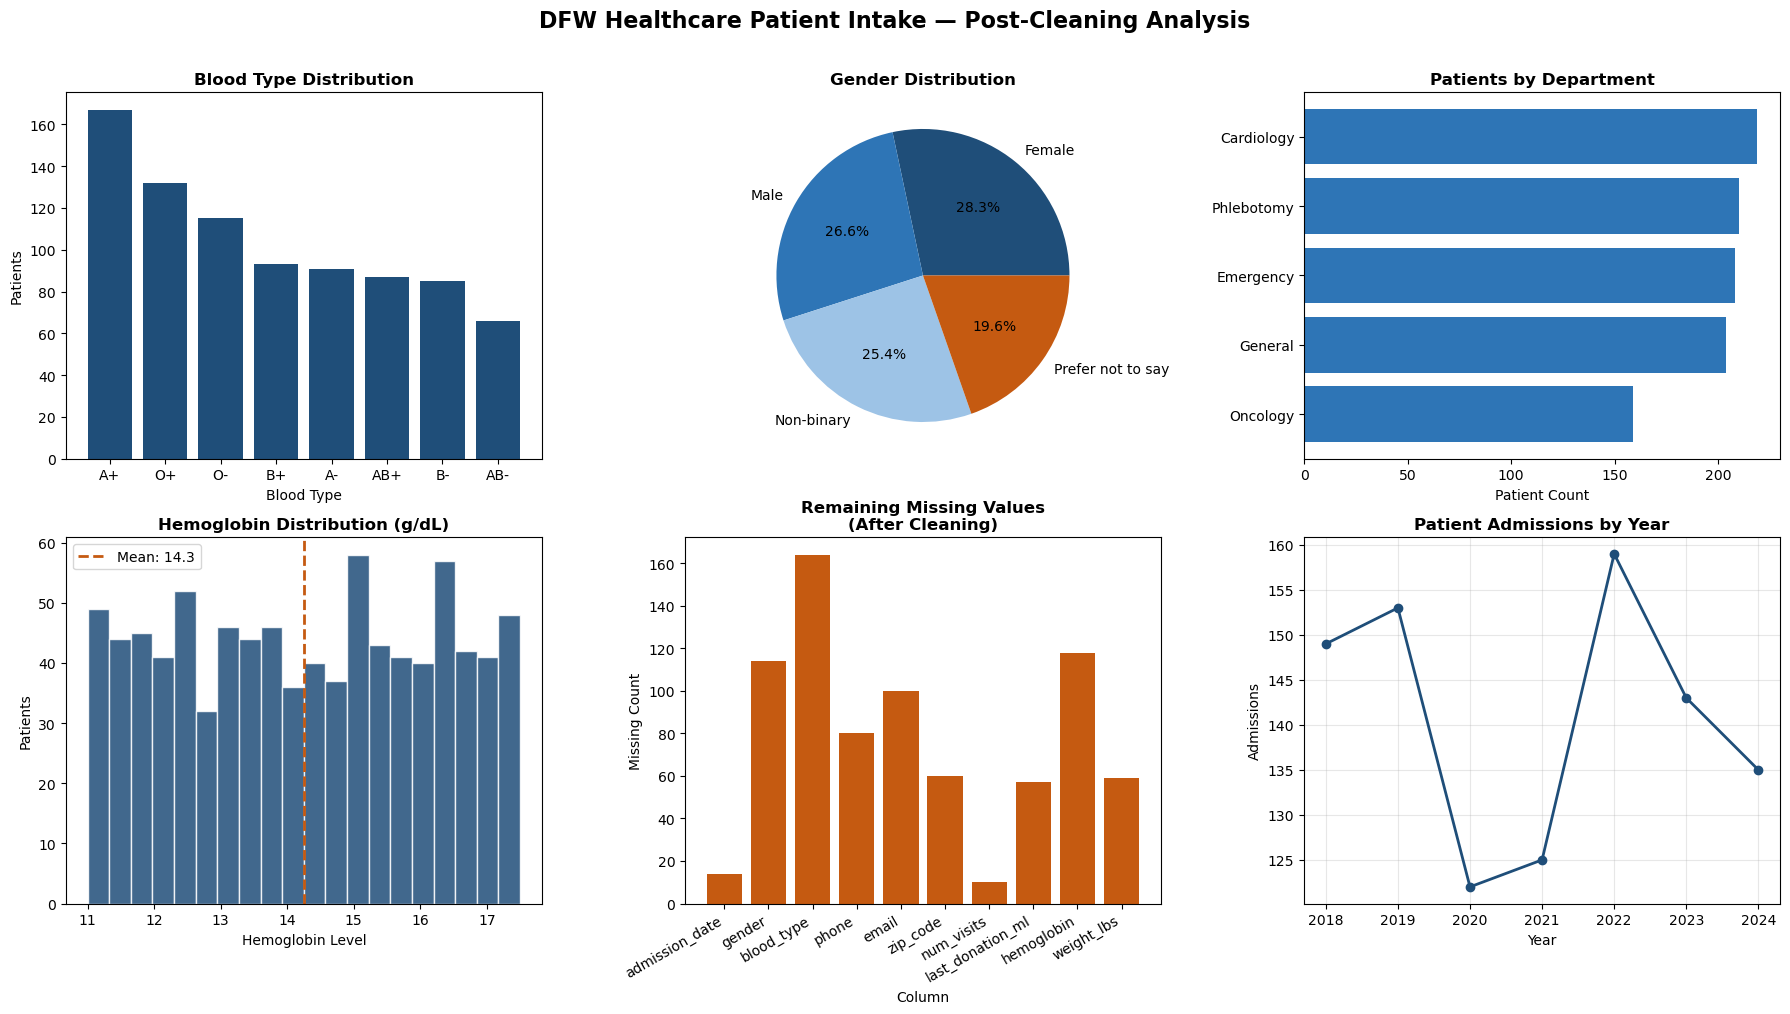

Dashboard saved.


In [19]:
fig = plt.figure(figsize=(18, 10))
fig.suptitle("DFW Healthcare Patient Intake — Post-Cleaning Analysis",
             fontsize=16, fontweight='bold', y=1.01)

gs = gridspec.GridSpec(2, 3, figure=fig)

BLUE   = '#1F4E79'
MED    = '#2E75B6'
LIGHT  = '#9DC3E6'
ORANGE = '#C55A11'

# Chart 1 — Blood type distribution
ax1 = fig.add_subplot(gs[0, 0])
bt = df['blood_type'].value_counts()
ax1.bar(bt.index, bt.values, color=BLUE)
ax1.set_title("Blood Type Distribution", fontweight='bold')
ax1.set_xlabel("Blood Type")
ax1.set_ylabel("Patients")

# Chart 2 — Gender distribution
ax2 = fig.add_subplot(gs[0, 1])
gd = df['gender'].value_counts()
ax2.pie(gd.values, labels=gd.index, autopct='%1.1f%%',
        colors=[BLUE, MED, LIGHT, ORANGE])
ax2.set_title("Gender Distribution", fontweight='bold')

# Chart 3 — Department distribution
ax3 = fig.add_subplot(gs[0, 2])
dp = df['department'].value_counts()
ax3.barh(dp.index, dp.values, color=MED)
ax3.set_title("Patients by Department", fontweight='bold')
ax3.set_xlabel("Patient Count")
ax3.invert_yaxis()

# Chart 4 — Hemoglobin distribution
ax4 = fig.add_subplot(gs[1, 0])
ax4.hist(df['hemoglobin'].dropna(), bins=20, color=BLUE,
         edgecolor='white', alpha=0.85)
ax4.set_title("Hemoglobin Distribution (g/dL)", fontweight='bold')
ax4.set_xlabel("Hemoglobin Level")
ax4.set_ylabel("Patients")
ax4.axvline(df['hemoglobin'].mean(), color=ORANGE, linestyle='--',
            linewidth=2, label=f"Mean: {df['hemoglobin'].mean():.1f}")
ax4.legend()

# Chart 5 — Missing values remaining
ax5 = fig.add_subplot(gs[1, 1])
missing_remaining = df.isnull().sum()
missing_remaining = missing_remaining[missing_remaining > 0]
ax5.bar(missing_remaining.index, missing_remaining.values, color=ORANGE)
ax5.set_title("Remaining Missing Values\n(After Cleaning)", fontweight='bold')
ax5.set_xlabel("Column")
ax5.set_ylabel("Missing Count")
plt.setp(ax5.xaxis.get_majorticklabels(), rotation=30, ha='right')

# Chart 6 — Admissions over time
ax6 = fig.add_subplot(gs[1, 2])
df['admission_year'] = df['admission_date'].dt.year
year_counts = df['admission_year'].value_counts().sort_index()
ax6.plot(year_counts.index, year_counts.values,
         color=BLUE, marker='o', linewidth=2)
ax6.set_title("Patient Admissions by Year", fontweight='bold')
ax6.set_xlabel("Year")
ax6.set_ylabel("Admissions")
ax6.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("healthcare_cleaning_dashboard.png", dpi=150, bbox_inches='tight')
plt.show()
print("Dashboard saved.")


## 6. Export Clean Dataset

The final missing value summary tells an uncomfortable truth. Across every column, gaps remain — contact information, gender, weight, donation history. Each one matters. Each one represents a patient whose record is incomplete and whose care is therefore uncertain.

But blood type and hemoglobin stand apart from the rest. These are not demographic fields. They are not convenience fields. They are the two data points most directly responsible for whether a patient lives or dies on a table.
    
A patient's life was cut short because someone did not write down the correct blood type. Not because of a complex system failure. Not because of a rare and unforeseeable circumstance. Because of negligence. Because somewhere in the chain of care, accurate data entry was treated as optional.
It was not optional. It never was.
    
This dataset has been cleaned to the fullest extent possible. The remaining missing values have been documented, flagged, and escalated for clinical follow-up. But no amount of data cleaning can undo what has already happened. It can only help ensure it does not happen again.
    
The hospital and its staff learned the hard way why precision matters. Every field in this dataset — every cell, every entry, every value — represents a human being who came to this institution trusting that the people caring for them were paying attention.
    
We owe them that attention. Every time. Without exception.

In [20]:
# Drop helper column before export
df_export = df.drop(columns=['admission_year'], errors='ignore')

df_export.to_csv("patient_data_CLEANED.csv", index=False)

print(f"Clean dataset exported: patient_data_CLEANED.csv")
print(f"Final shape: {df_export.shape}")
print(f"\nFinal missing value summary:")
final_missing = df_export.isnull().sum()
print(final_missing[final_missing > 0])


Clean dataset exported: patient_data_CLEANED.csv
Final shape: (1000, 16)

Final missing value summary:
admission_date       14
gender              114
blood_type          164
phone                80
email               100
zip_code             60
num_visits           10
last_donation_ml     57
hemoglobin          118
weight_lbs           59
dtype: int64


## 7. Cleaning Summary

| Issue | Records Affected | Fix Applied |
|---|---|---|
| Inconsistent date formats | ~400 | Parsed with multiple format detection |
| Inconsistent phone formats | ~1050 | Extracted digits, reformatted to (XXX) XXX-XXXX |
| Messy blood type values | ~300 | Mapped to 8 standard values |
| Messy gender values | ~350 | Mapped to 4 standard categories |
| Messy state values | ~200 | Mapped all Texas variants to TX |
| Messy department names | ~300 | Mapped to 5 standard departments |
| Missing values | Various | Documented, not imputed (business decision required) |
| Impossible outliers | ~75 | Nulled — flagged for clinical review |
| Duplicate records | 50 | Removed keeping first occurrence |
| Mixed case emails | ~150 | Lowercased and stripped |
| Whitespace in names | ~80 | Stripped and title-cased |
| Future admission dates | 15 | Nulled — flagged for review |
| Negative donation values | 10 | Nulled — impossible values |

**Key decision documented:** Missing values were left as null rather than imputed. In a healthcare context, imputing clinical values (hemoglobin, blood type) without domain expert approval is inappropriate and potentially dangerous.

---
*Built by Alejandro Molina | github.com/chooseyourtacoday*
